<a href="https://colab.research.google.com/github/acscalera7/retirement-monte-carlo/blob/main/retirement_monte_carlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

I built a Monte Carlo model in Python with vibe coding that tests a retirement plan against 10,000 possible market futures to estimate the odds the money lasts. For a sample client, the plan only worked about 30% of the time as written, but working two more years and spending a little less pushed it above 80%.


In [ ]:
print("Hello, finance")

Hello, finance


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ===== CLIENT INPUTS (change these any time) =====
current_age = 30
retire_age = 65
end_age = 95                # the money needs to last to this age

current_savings = 50_000    # saved so far
annual_savings = 12_000     # added each year while working
annual_spending = 70_000    # withdrawn each year once retired

stock_pct = 0.70            # 70% stocks, 30% bonds

# ===== MARKET ASSUMPTIONS (after inflation) =====
stock_return, stock_vol = 0.05, 0.16    # average yearly return, typical swing
bond_return, bond_vol = 0.02, 0.06

n_sims = 10_000             # how many possible futures to test

In [ ]:
print(retire_age - current_age)

35


Average portfolio return: 4.1%
Savings at retirement: $1,105,835
Savings at age 95: $0


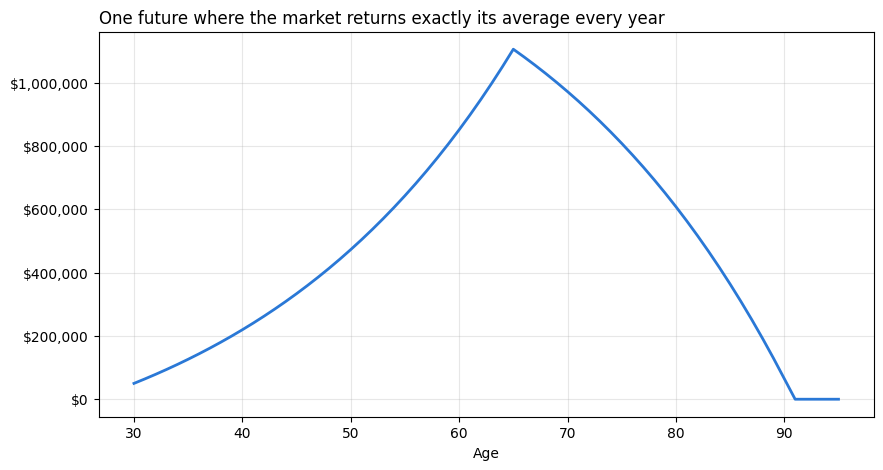

In [ ]:
avg_return = stock_pct * stock_return + (1 - stock_pct) * bond_return

balance = current_savings
ages = []
steady_balances = []

for age in range(current_age, end_age + 1):
    ages.append(age)
    steady_balances.append(balance)
    balance = balance * (1 + avg_return)      # one year of growth
    if age < retire_age:
        balance = balance + annual_savings    # working: add savings
    else:
        balance = balance - annual_spending   # retired: withdraw
    if balance < 0:
        balance = 0                           # can't go below zero

print(f"Average portfolio return: {avg_return:.1%}")
print(f"Savings at retirement: ${steady_balances[retire_age - current_age]:,.0f}")
print(f"Savings at age {end_age}: ${steady_balances[-1]:,.0f}")

plt.figure(figsize=(10, 5))
plt.plot(ages, steady_balances, color="#2a78d6", lw=2)
plt.title("One future where the market returns exactly its average every year", loc="left")
plt.xlabel("Age")
plt.gca().yaxis.set_major_formatter("${x:,.0f}")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ===== CLIENT INPUTS (change these any time) =====
current_age = 30
retire_age = 65
end_age = 95                # the money needs to last to this age

current_savings = 50_000    # saved so far
annual_savings = 12_000     # added each year while working
annual_spending = 55_000    # withdrawn each year once retired

stock_pct = 0.70            # 70% stocks, 30% bonds

# ===== MARKET ASSUMPTIONS (after inflation) =====
stock_return, stock_vol = 0.05, 0.16    # average yearly return, typical swing
bond_return, bond_vol = 0.02, 0.06

n_sims = 10_000             # how many possible futures to test

Average portfolio return: 4.1%
Savings at retirement: $1,105,835
Savings at age 95: $554,871


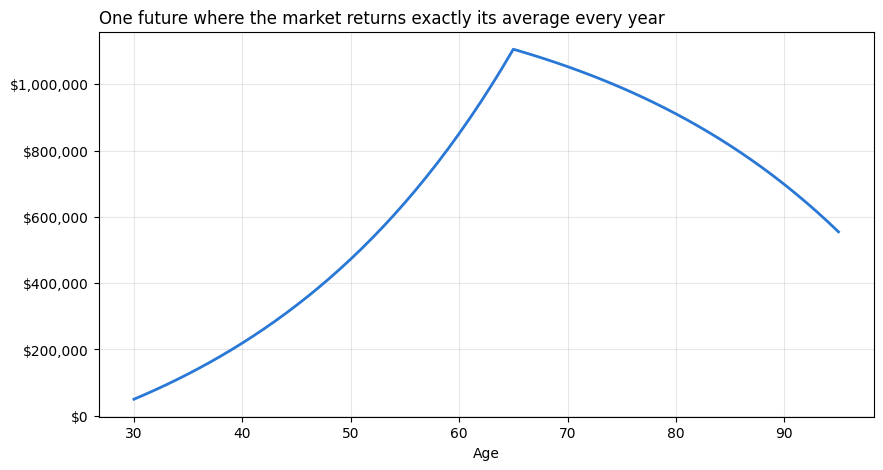

In [ ]:
avg_return = stock_pct * stock_return + (1 - stock_pct) * bond_return

balance = current_savings
ages = []
steady_balances = []

for age in range(current_age, end_age + 1):
    ages.append(age)
    steady_balances.append(balance)
    balance = balance * (1 + avg_return)      # one year of growth
    if age < retire_age:
        balance = balance + annual_savings    # working: add savings
    else:
        balance = balance - annual_spending   # retired: withdraw
    if balance < 0:
        balance = 0                           # can't go below zero

print(f"Average portfolio return: {avg_return:.1%}")
print(f"Savings at retirement: ${steady_balances[retire_age - current_age]:,.0f}")
print(f"Savings at age {end_age}: ${steady_balances[-1]:,.0f}")

plt.figure(figsize=(10, 5))
plt.plot(ages, steady_balances, color="#2a78d6", lw=2)
plt.title("One future where the market returns exactly its average every year", loc="left")
plt.xlabel("Age")
plt.gca().yaxis.set_major_formatter("${x:,.0f}")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ===== CLIENT INPUTS (change these any time) =====
current_age = 30
retire_age = 65
end_age = 95                # the money needs to last to this age

current_savings = 50_000    # saved so far
annual_savings = 12_000     # added each year while working
annual_spending = 70_000    # withdrawn each year once retired

stock_pct = 0.70            # 70% stocks, 30% bonds

# ===== MARKET ASSUMPTIONS (after inflation) =====
stock_return, stock_vol = 0.05, 0.16    # average yearly return, typical swing
bond_return, bond_vol = 0.02, 0.06

n_sims = 10_000             # how many possible futures to test

Average portfolio return: 4.1%
Savings at retirement: $1,105,835
Savings at age 95: $0


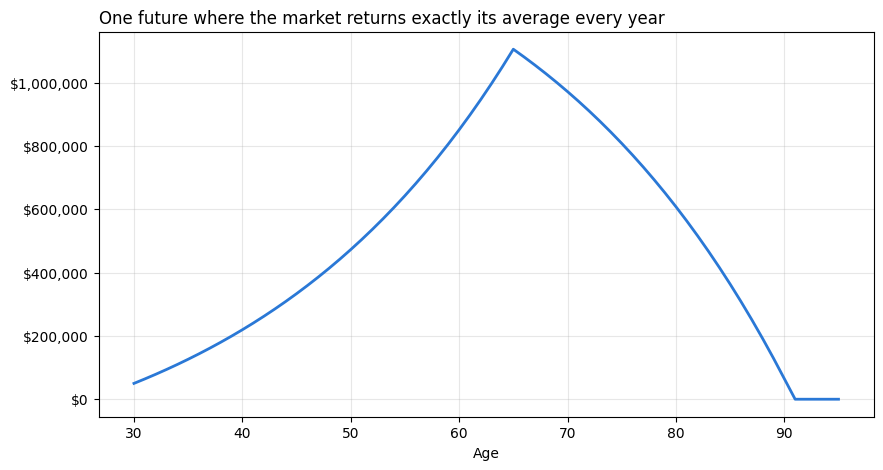

In [ ]:
avg_return = stock_pct * stock_return + (1 - stock_pct) * bond_return

balance = current_savings
ages = []
steady_balances = []

for age in range(current_age, end_age + 1):
    ages.append(age)
    steady_balances.append(balance)
    balance = balance * (1 + avg_return)      # one year of growth
    if age < retire_age:
        balance = balance + annual_savings    # working: add savings
    else:
        balance = balance - annual_spending   # retired: withdraw
    if balance < 0:
        balance = 0                           # can't go below zero

print(f"Average portfolio return: {avg_return:.1%}")
print(f"Savings at retirement: ${steady_balances[retire_age - current_age]:,.0f}")
print(f"Savings at age {end_age}: ${steady_balances[-1]:,.0f}")

plt.figure(figsize=(10, 5))
plt.plot(ages, steady_balances, color="#2a78d6", lw=2)
plt.title("One future where the market returns exactly its average every year", loc="left")
plt.xlabel("Age")
plt.gca().yaxis.set_major_formatter("${x:,.0f}")
plt.grid(alpha=0.3)
plt.show()

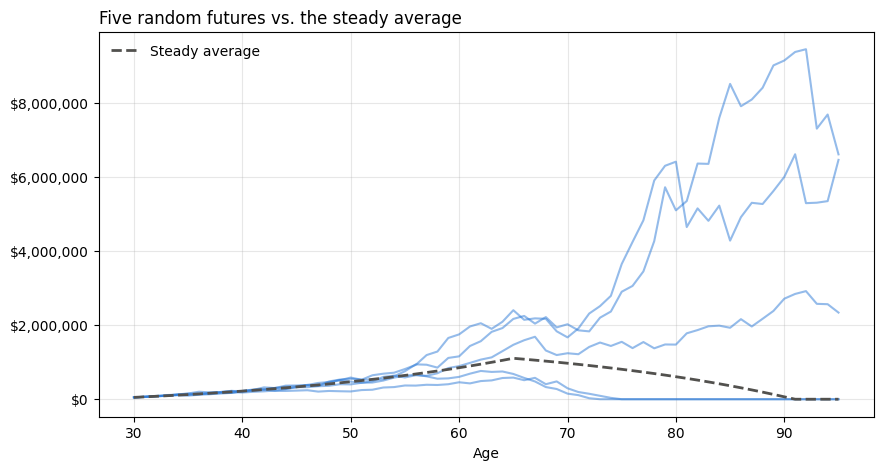

In [ ]:
rng = np.random.default_rng()

def simulate_one_life():
    years = end_age - current_age + 1
    stock_returns = rng.normal(stock_return, stock_vol, years)   # a random return for every year
    bond_returns = rng.normal(bond_return, bond_vol, years)

    balance = current_savings
    balances = []
    for i in range(years):
        age = current_age + i
        balances.append(balance)
        r = stock_pct * stock_returns[i] + (1 - stock_pct) * bond_returns[i]
        balance = balance * (1 + r)
        if age < retire_age:
            balance = balance + annual_savings
        else:
            balance = balance - annual_spending
        if balance < 0:
            balance = 0
    return balances

plt.figure(figsize=(10, 5))
for _ in range(5):
    plt.plot(ages, simulate_one_life(), color="#2a78d6", alpha=0.5, lw=1.5)
plt.plot(ages, steady_balances, color="#52514e", lw=2, ls="--", label="Steady average")
plt.title("Five random futures vs. the steady average", loc="left")
plt.xlabel("Age")
plt.gca().yaxis.set_major_formatter("${x:,.0f}")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

In [ ]:
results = []
for sim in range(n_sims):
    results.append(simulate_one_life())
results = np.array(results)    # a grid: one row per future, one column per age

print(results.shape)

success_rate = (results[:, -1] > 0).mean()    # share of futures with money left at the end
median_at_retirement = np.median(results[:, retire_age - current_age])

print(f"Median savings at retirement: ${median_at_retirement:,.0f}")
print(f"Chance the money lasts to age {end_age}: {success_rate:.0%}")

(10000, 66)
Median savings at retirement: $990,944
Chance the money lasts to age 95: 31%


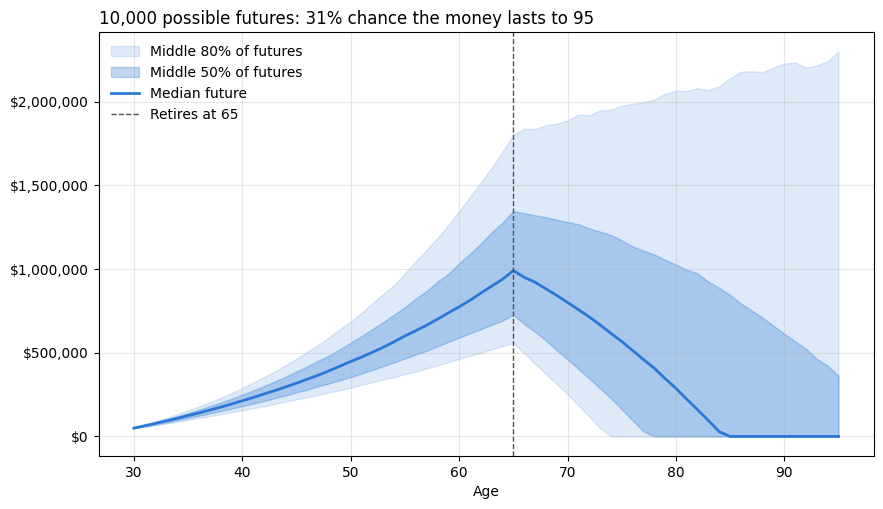

In [ ]:
p10, p25, p50, p75, p90 = np.percentile(results, [10, 25, 50, 75, 90], axis=0)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.fill_between(ages, p10, p90, color="#2a78d6", alpha=0.15, label="Middle 80% of futures")
ax.fill_between(ages, p25, p75, color="#2a78d6", alpha=0.30, label="Middle 50% of futures")
ax.plot(ages, p50, color="#2a78d6", lw=2, label="Median future")
ax.axvline(retire_age, color="#52514e", ls="--", lw=1, label=f"Retires at {retire_age}")
ax.set_title(f"10,000 possible futures: {success_rate:.0%} chance the money lasts to {end_age}", loc="left")
ax.set_xlabel("Age")
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.3)
plt.show()

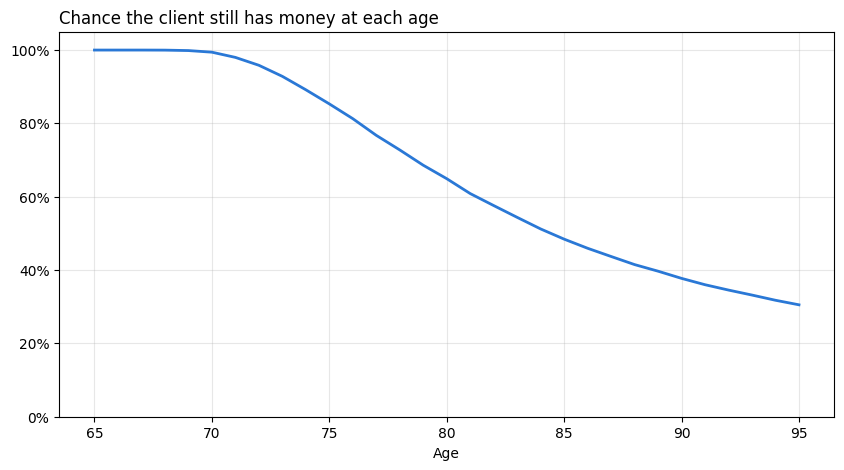

In [ ]:
start = retire_age - current_age
still_has_money = (results > 0).mean(axis=0)    # share of futures with money left, at each age

plt.figure(figsize=(10, 5))
plt.plot(ages[start:], still_has_money[start:], color="#2a78d6", lw=2)
plt.title("Chance the client still has money at each age", loc="left")
plt.xlabel("Age")
plt.ylim(0, 1.05)
plt.gca().yaxis.set_major_formatter("{x:.0%}")
plt.grid(alpha=0.3)
plt.show()

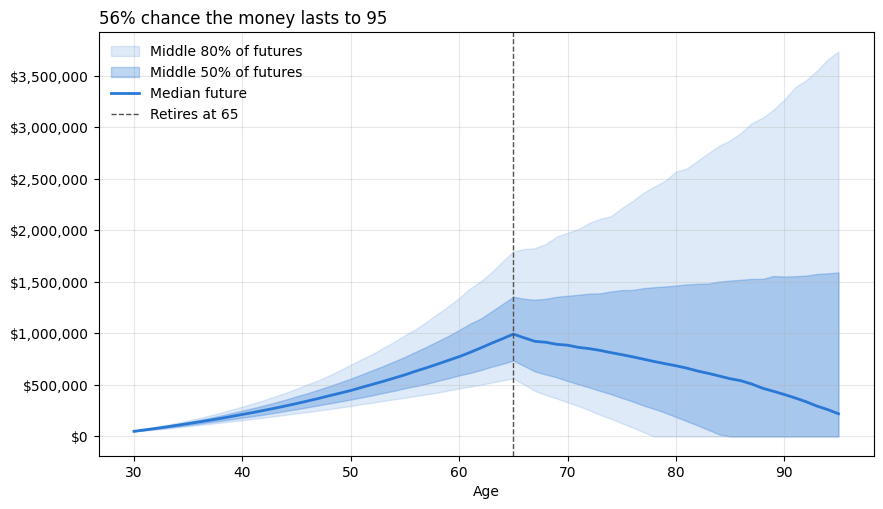

In [ ]:
social_security = 24_000    # yearly benefit, today's dollars
ss_age = 67                 # age benefits start

def run_plan(retire_age, annual_spending, stock_pct, n_sims=2_000):
    years = end_age - current_age + 1
    results = np.zeros((n_sims, years))
    for sim in range(n_sims):
        stock_returns = rng.normal(stock_return, stock_vol, years)
        bond_returns = rng.normal(bond_return, bond_vol, years)
        balance = current_savings
        for i in range(years):
            age = current_age + i
            results[sim, i] = balance
            r = stock_pct * stock_returns[i] + (1 - stock_pct) * bond_returns[i]
            balance = balance * (1 + r)
            if age < retire_age:
                balance = balance + annual_savings
            else:
                balance = balance - annual_spending
            if age >= ss_age:
                balance = balance + social_security    # new: Social Security income
            if balance < 0:
                balance = 0
    success_rate = (results[:, -1] > 0).mean()
    return results, success_rate

def plot_fan(results, success_rate, retire_age):
    p10, p25, p50, p75, p90 = np.percentile(results, [10, 25, 50, 75, 90], axis=0)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.fill_between(ages, p10, p90, color="#2a78d6", alpha=0.15, label="Middle 80% of futures")
    ax.fill_between(ages, p25, p75, color="#2a78d6", alpha=0.30, label="Middle 50% of futures")
    ax.plot(ages, p50, color="#2a78d6", lw=2, label="Median future")
    ax.axvline(retire_age, color="#52514e", ls="--", lw=1, label=f"Retires at {retire_age}")
    ax.set_title(f"{success_rate:.0%} chance the money lasts to {end_age}", loc="left")
    ax.set_xlabel("Age")
    ax.yaxis.set_major_formatter("${x:,.0f}")
    ax.legend(frameon=False, loc="upper left")
    ax.grid(alpha=0.3)
    plt.show()

results, success_rate = run_plan(retire_age, annual_spending, stock_pct, n_sims=10_000)
plot_fan(results, success_rate, retire_age)

In [ ]:
import pandas as pd

retire_ages = [60, 62, 65, 67, 70]
spending_levels = [50_000, 60_000, 70_000, 80_000]

table = pd.DataFrame(index=spending_levels, columns=retire_ages, dtype=float)
for spending in spending_levels:
    for age in retire_ages:
        _, rate = run_plan(age, spending, stock_pct)
        table.loc[spending, age] = rate

table.index = [f"Spend ${s:,.0f}/yr" for s in spending_levels]
table.columns = [f"Retire at {a}" for a in retire_ages]
display(table.style.format("{:.0%}").background_gradient(cmap="Greens", vmin=0, vmax=1))

,Retire at 60,Retire at 62,Retire at 65,Retire at 67,Retire at 70
"Spend $50,000/yr",60%,71%,87%,93%,98%
"Spend $60,000/yr",39%,51%,72%,82%,92%
"Spend $70,000/yr",23%,36%,54%,70%,85%
"Spend $80,000/yr",15%,25%,42%,55%,73%


In [ ]:
from ipywidgets import interact, IntSlider, FloatSlider

def explore(retire_age, annual_spending, stock_pct):
    results, success_rate = run_plan(retire_age, annual_spending, stock_pct)
    plot_fan(results, success_rate, retire_age)

interact(explore,
         retire_age=IntSlider(value=65, min=55, max=75, description="Retire at", continuous_update=False),
         annual_spending=IntSlider(value=70_000, min=30_000, max=120_000, step=5_000,
                                   description="Spending", continuous_update=False),
         stock_pct=FloatSlider(value=0.7, min=0, max=1, step=0.1,
                               description="Stocks", continuous_update=False));

interactive(children=(IntSlider(value=65, continuous_update=False, description='Retire at', max=75, min=55), I…